In [1]:
!pip install tensorflow matplotlib seaborn pandas scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Dense, Dropout,
    BatchNormalization, LayerNormalization,
    Rescaling, RandomRotation, RandomFlip
)

from tensorflow.keras.regularizers import l1, l2, l1_l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("Training Dataset:", X_train_full.shape)
print("Testing Dataset:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Dataset: (60000, 28, 28)
Testing Dataset: (10000, 28, 28)


In [4]:
# Normalize pixel values
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Split training and validation datasets
X_train = X_train_full[:50000]
y_train = y_train_full[:50000]

X_val = X_train_full[50000:]
y_val = y_train_full[50000:]

# Flatten images into 784-dimensional vectors
X_train = X_train.reshape(-1, 784)
X_val = X_val.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (50000, 784)
Validation: (10000, 784)
Testing: (10000, 784)


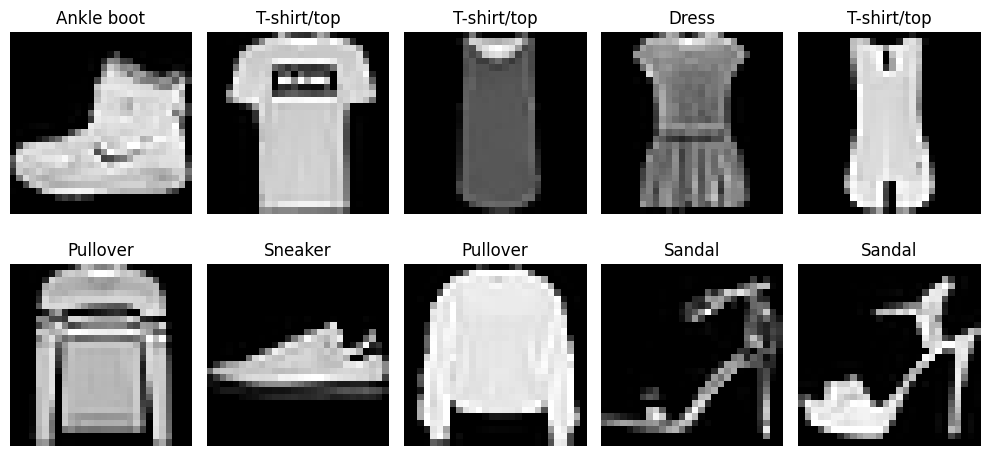

In [5]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover',
    'Dress', 'Coat', 'Sandal',
    'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
# Convert images to 28x28x1 format
X_train_img = X_train.reshape(-1, 28, 28, 1)
X_val_img = X_val.reshape(-1, 28, 28, 1)
X_test_img = X_test.reshape(-1, 28, 28, 1)

print("Training image shape:", X_train_img.shape)

Training image shape: (50000, 28, 28, 1)


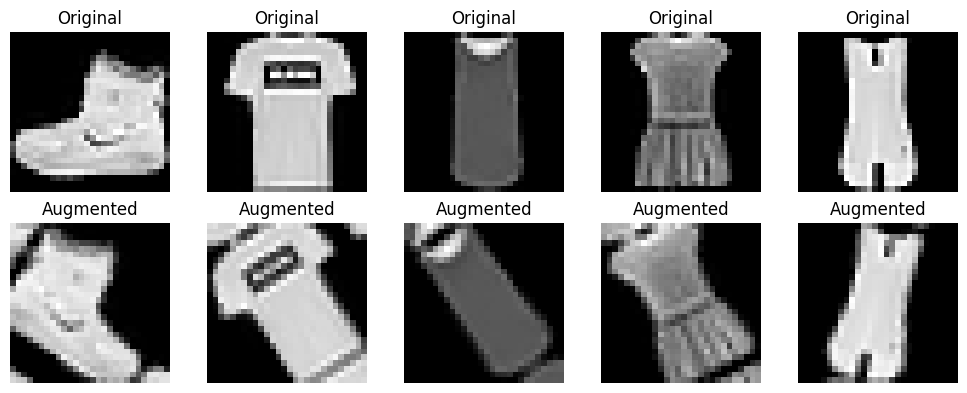

In [7]:
data_augmentation = Sequential([
    RandomRotation(0.1),
    RandomFlip("horizontal")
])

# Display augmented images
sample_images = X_train_img[:5]

augmented_images = data_augmentation(
    sample_images,
    training=True
)

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].squeeze(), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(augmented_images[i].numpy().squeeze(), cmap='gray')
    plt.title("Augmented")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
def build_model(
    dropout=False,
    regularization=None,
    normalization=None,
    augmentation=False
):

    model = Sequential()

    model.add(Input(shape=(28, 28, 1)))

    # Data augmentation
    if augmentation:
        model.add(RandomRotation(0.1))
        model.add(RandomFlip("horizontal"))

    # Flatten image
    model.add(tf.keras.layers.Flatten())

    # Select regularization
    if regularization == "L1":
        reg = l1(0.0001)

    elif regularization == "L2":
        reg = l2(0.001)

    elif regularization == "L1_L2":
        reg = l1_l2(l1=0.0001, l2=0.001)

    else:
        reg = None

    # Three hidden layers
    for i in range(3):

        model.add(Dense(
            256,
            use_bias=(normalization is None),
            kernel_regularizer=reg
        ))

        # Normalization
        if normalization == "Batch":
            model.add(BatchNormalization())

        elif normalization == "Layer":
            model.add(LayerNormalization())

        model.add(tf.keras.layers.ReLU())

        # Dropout
        if dropout:
            model.add(Dropout(0.5))

    # Output layer
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [9]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [10]:
experiments = {
    "Baseline": {
        "dropout": False,
        "regularization": None,
        "normalization": None,
        "augmentation": False
    },

    "Dropout": {
        "dropout": True,
        "regularization": None,
        "normalization": None,
        "augmentation": False
    },

    "L1": {
        "dropout": False,
        "regularization": "L1",
        "normalization": None,
        "augmentation": False
    },

    "L2": {
        "dropout": False,
        "regularization": "L2",
        "normalization": None,
        "augmentation": False
    },

    "Augmentation": {
        "dropout": False,
        "regularization": None,
        "normalization": None,
        "augmentation": True
    },

    "Batch Normalization": {
        "dropout": False,
        "regularization": None,
        "normalization": "Batch",
        "augmentation": False
    },

    "Layer Normalization": {
        "dropout": False,
        "regularization": None,
        "normalization": "Layer",
        "augmentation": False
    },

    "Combined": {
        "dropout": True,
        "regularization": "L2",
        "normalization": "Batch",
        "augmentation": True
    }
}

In [11]:
models = {}
histories = {}
results = {}

for name, config in experiments.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(**config)

    start_time = time.time()

    history = model.fit(
        X_train_img,
        y_train,
        validation_data=(X_val_img, y_val),
        epochs=30,
        batch_size=128,
        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True,
                verbose=1
            )
        ],
        verbose=1
    )

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        X_test_img,
        y_test,
        verbose=0
    )

    best_epoch = np.argmin(history.history['val_loss'])

    models[name] = model
    histories[name] = history

    results[name] = {
        "Training Loss": history.history['loss'][best_epoch],
        "Validation Loss": history.history['val_loss'][best_epoch],
        "Validation Accuracy": history.history['val_accuracy'][best_epoch] * 100,
        "Test Accuracy": test_accuracy * 100,
        "Test Loss": test_loss,
        "Epochs Completed": len(history.history['loss']),
        "Best Epoch": best_epoch + 1,
        "Training Time": training_time
    }

    print("Best Epoch:", best_epoch + 1)
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(training_time, 2), "seconds")


Training: Baseline
Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8139 - loss: 0.5205 - val_accuracy: 0.8490 - val_loss: 0.4209
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8665 - loss: 0.3671 - val_accuracy: 0.8625 - val_loss: 0.3768
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8797 - loss: 0.3270 - val_accuracy: 0.8697 - val_loss: 0.3629
Epoch 4/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8884 - loss: 0.3021 - val_accuracy: 0.8744 - val_loss: 0.3524
Epoch 5/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8952 - loss: 0.2817 - val_accuracy: 0.8759 - val_loss: 0.3580
Epoch 6/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9010 - loss: 0.2655 - val_accuracy: 0.8759 - val_loss: 0.3573
Epoch 7/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9048 - loss: 0.2534 - val_accuracy: 0.8757 - val_loss: 0.3586
Epoch 8/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9092 - loss: 0.24

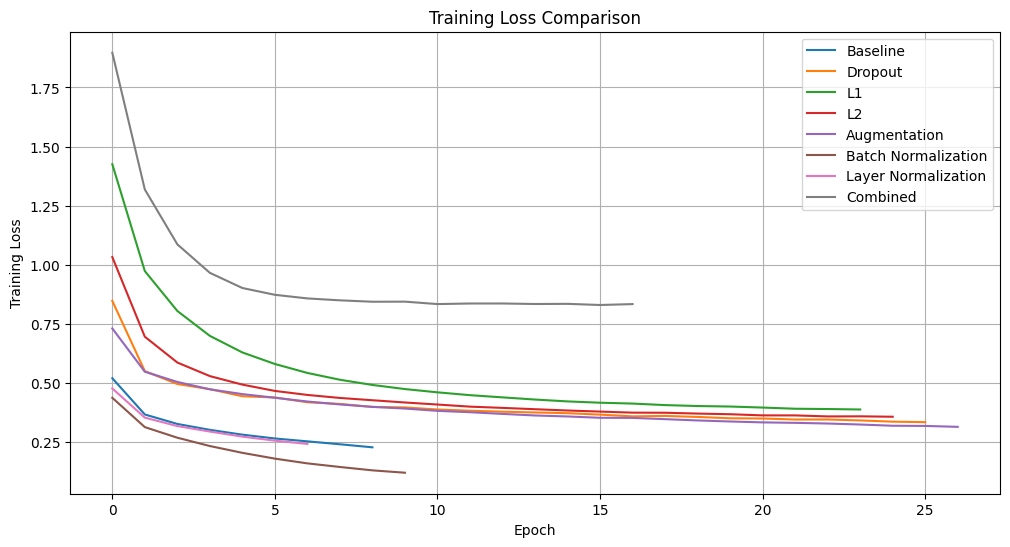

In [12]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['loss'],
        label=name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend()
plt.grid()
plt.show()

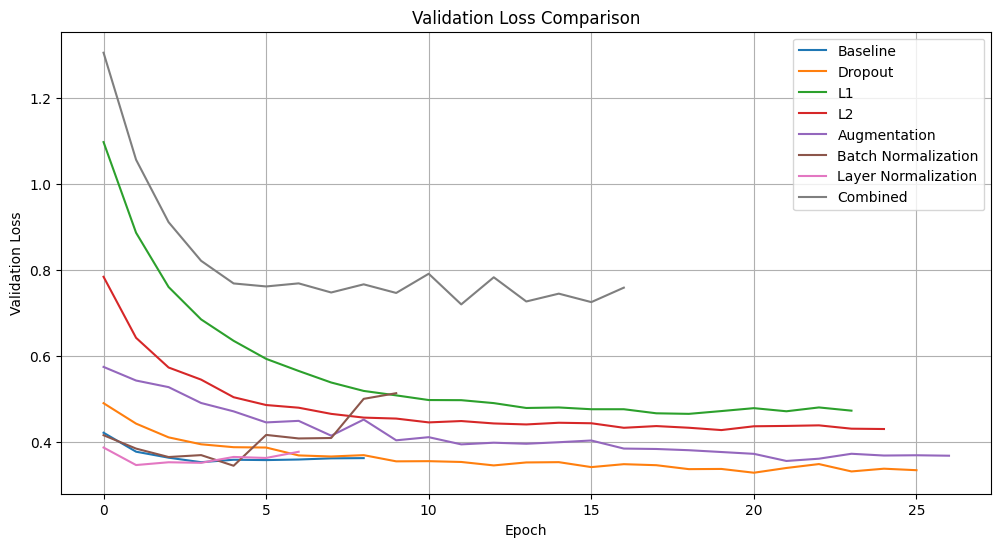

In [13]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['val_loss'],
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.legend()
plt.grid()
plt.show()

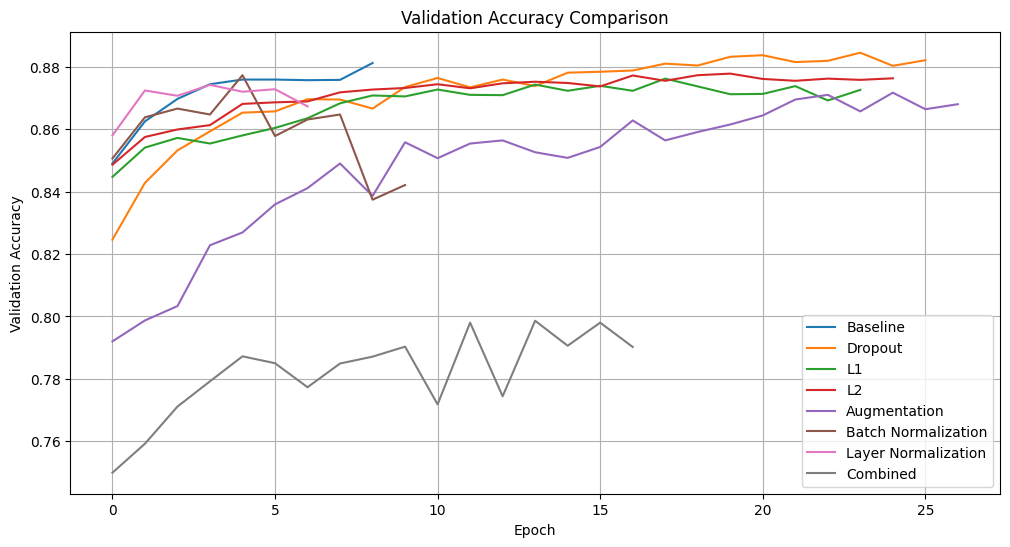

In [14]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

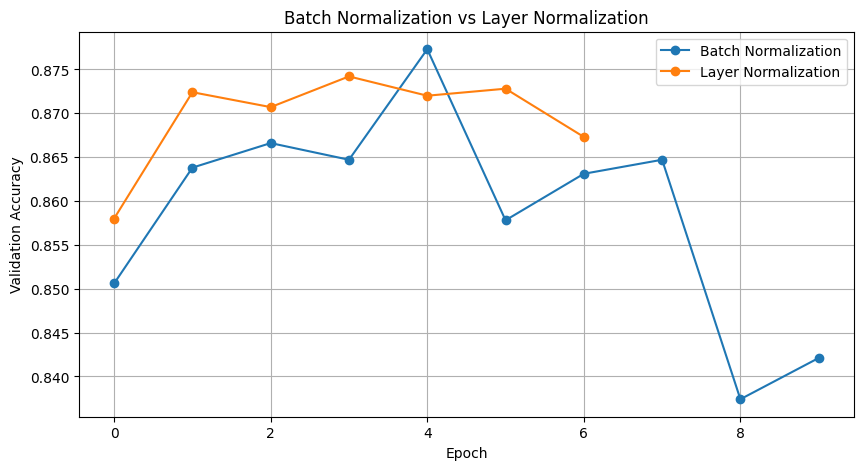

In [15]:
plt.figure(figsize=(10, 5))

for name in ["Batch Normalization", "Layer Normalization"]:

    plt.plot(
        histories[name].history['val_accuracy'],
        marker='o',
        label=name
    )

plt.title("Batch Normalization vs Layer Normalization")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

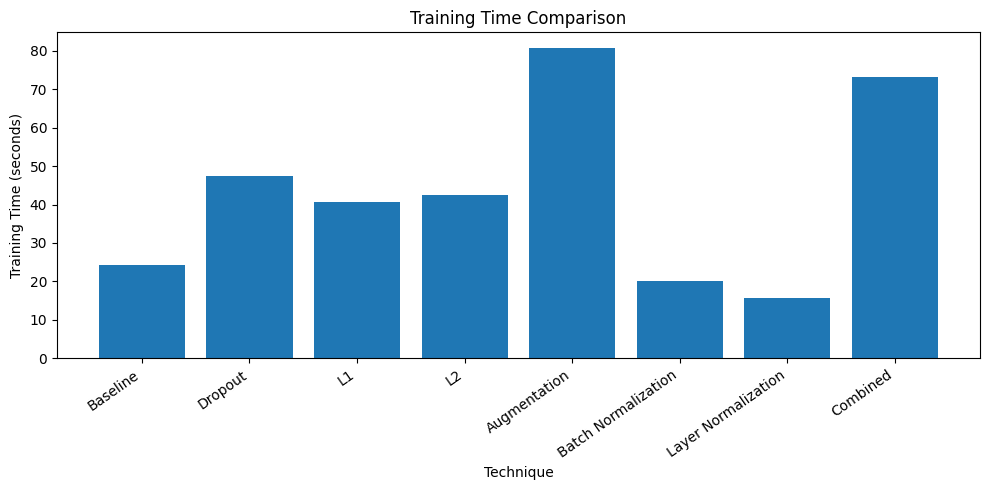

In [16]:
results_df = pd.DataFrame(results).T

plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df['Training Time']
)

plt.title("Training Time Comparison")
plt.xlabel("Technique")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

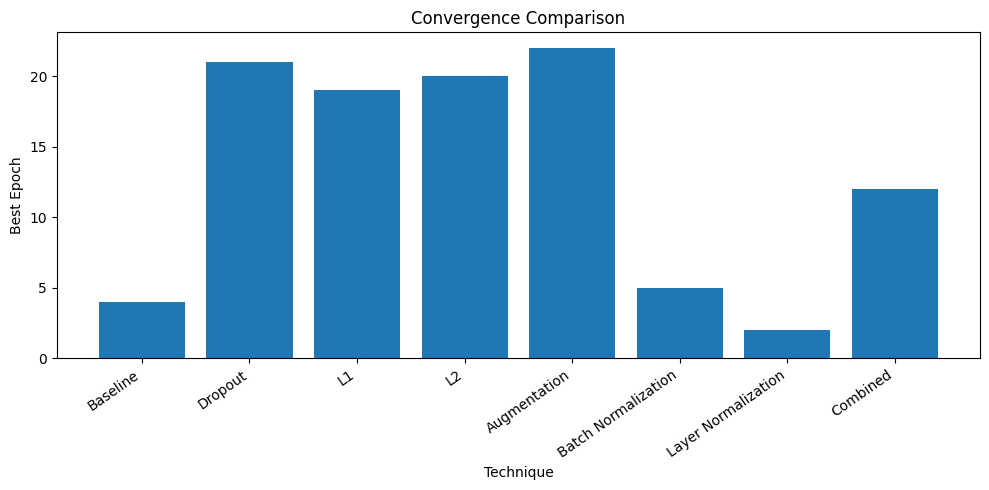

In [17]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df['Best Epoch']
)

plt.title("Convergence Comparison")
plt.xlabel("Technique")
plt.ylabel("Best Epoch")
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

In [18]:
train_accuracies = {}

for name, model in models.items():

    loss, accuracy = model.evaluate(
        X_train_img,
        y_train,
        verbose=0
    )

    train_accuracies[name] = accuracy * 100

results_df["Training Accuracy"] = [
    train_accuracies[name] for name in results_df.index
]

results_df["Generalization Gap"] = (
    results_df["Training Accuracy"] -
    results_df["Test Accuracy"]
)

print(results_df[
    ["Training Accuracy", "Validation Accuracy",
     "Test Accuracy", "Generalization Gap"]
].round(2))

                     Training Accuracy  Validation Accuracy  Test Accuracy  \
Baseline                         89.43                87.44          86.67   
Dropout                          90.21                88.37          87.61   
L1                               89.61                87.37          86.82   
L2                               90.44                87.78          87.45   
Augmentation                     88.55                86.95          86.19   
Batch Normalization              91.33                87.73          86.95   
Layer Normalization              88.87                87.24          86.43   
Combined                         80.16                79.80          78.85   

                     Generalization Gap  
Baseline                           2.76  
Dropout                            2.60  
L1                                 2.79  
L2                                 2.99  
Augmentation                       2.36  
Batch Normalization                4.38  
Lay

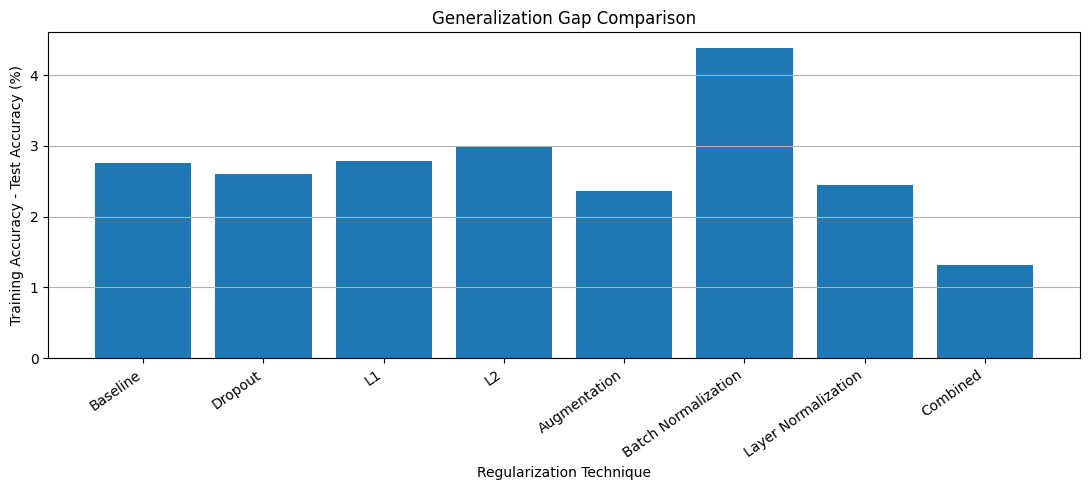

In [19]:
plt.figure(figsize=(11, 5))

plt.bar(
    results_df.index,
    results_df["Generalization Gap"]
)

plt.title("Generalization Gap Comparison")
plt.xlabel("Regularization Technique")
plt.ylabel("Training Accuracy - Test Accuracy (%)")

plt.xticks(rotation=35, ha='right')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [20]:
print("\nFINAL COMPARISON OF ALL TECHNIQUES")

print(
    results_df.round(4).to_string()
)


FINAL COMPARISON OF ALL TECHNIQUES
                     Training Loss  Validation Loss  Validation Accuracy  Test Accuracy  Test Loss  Epochs Completed  Best Epoch  Training Time  Training Accuracy  Generalization Gap
Baseline                    0.3021           0.3524                87.44          86.67     0.3719               9.0         4.0        24.2768             89.434               2.764
Dropout                     0.3500           0.3279                88.37          87.61     0.3494              26.0        21.0        47.5157             90.206               2.596
L1                          0.4028           0.4648                87.37          86.82     0.4830              24.0        19.0        40.7773             89.612               2.792
L2                          0.3681           0.4271                87.78          87.45     0.4452              25.0        20.0        42.5523             90.440               2.990
Augmentation                0.3317           0.35

In [21]:
best_model_name = results_df["Test Accuracy"].idxmax()

print("Best Performing Model:", best_model_name)

print(
    "Test Accuracy:",
    round(results_df.loc[best_model_name, "Test Accuracy"], 2),
    "%"
)

print(
    "Training Time:",
    round(results_df.loc[best_model_name, "Training Time"], 2),
    "seconds"
)

Best Performing Model: Dropout
Test Accuracy: 87.61 %
Training Time: 47.52 seconds
